<a href="https://colab.research.google.com/github/y0n1k/ml-labs/blob/main/ML_Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 2. Логістична регресія та федеративне навчання

**Мета:** Зрозуміти архітектуру багатокласової логістичної регресії, навчитися самостійно реалізовувати модель засобами Python (`numpy` / `torch`), зрозуміти принципи федеративного навчання, правильно розподілити дані між клієнтами та сервером, реалізувати агрегацію ваг та проаналізувати базові ефекти розподіленого навчання.

---

## Етап 1. Дослідження даних та попередня обробка

У цій роботі використано **Dry Bean Dataset** із Kaggle (завантажений у форматі Excel-файлу `Dry_Bean_Dataset.xlsx`).

### 1. Первинний аналіз даних (EDA) та відбір ознак

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, log_loss, confusion_matrix

# Завантаження датасету
xls = pd.ExcelFile('Dry_Bean_Dataset.xlsx')
df = pd.read_excel('Dry_Bean_Dataset.xlsx', sheet_name='Dry_Beans_Dataset')

print(f"Розмір датасету: {df.shape}")
print("\nТипи ознак:")
print(df.dtypes)
print("\nКількість пропущених значень:")
print(df.isnull().sum())
print("\nРозподіл цільової змінної (Class):")
print(df['Class'].value_counts())

Розмір датасету: (13611, 17)

Типи ознак:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

Кількість пропущених значень:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Розподіл цільової змінної (Class):
Class
DERMASON    3546
SIRA        2636
SEKER   

/tmp/ipykernel_658/2084059061.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Class', data=df, order=df['Class'].value_counts().index, ax=axes[0], palette='viridis')


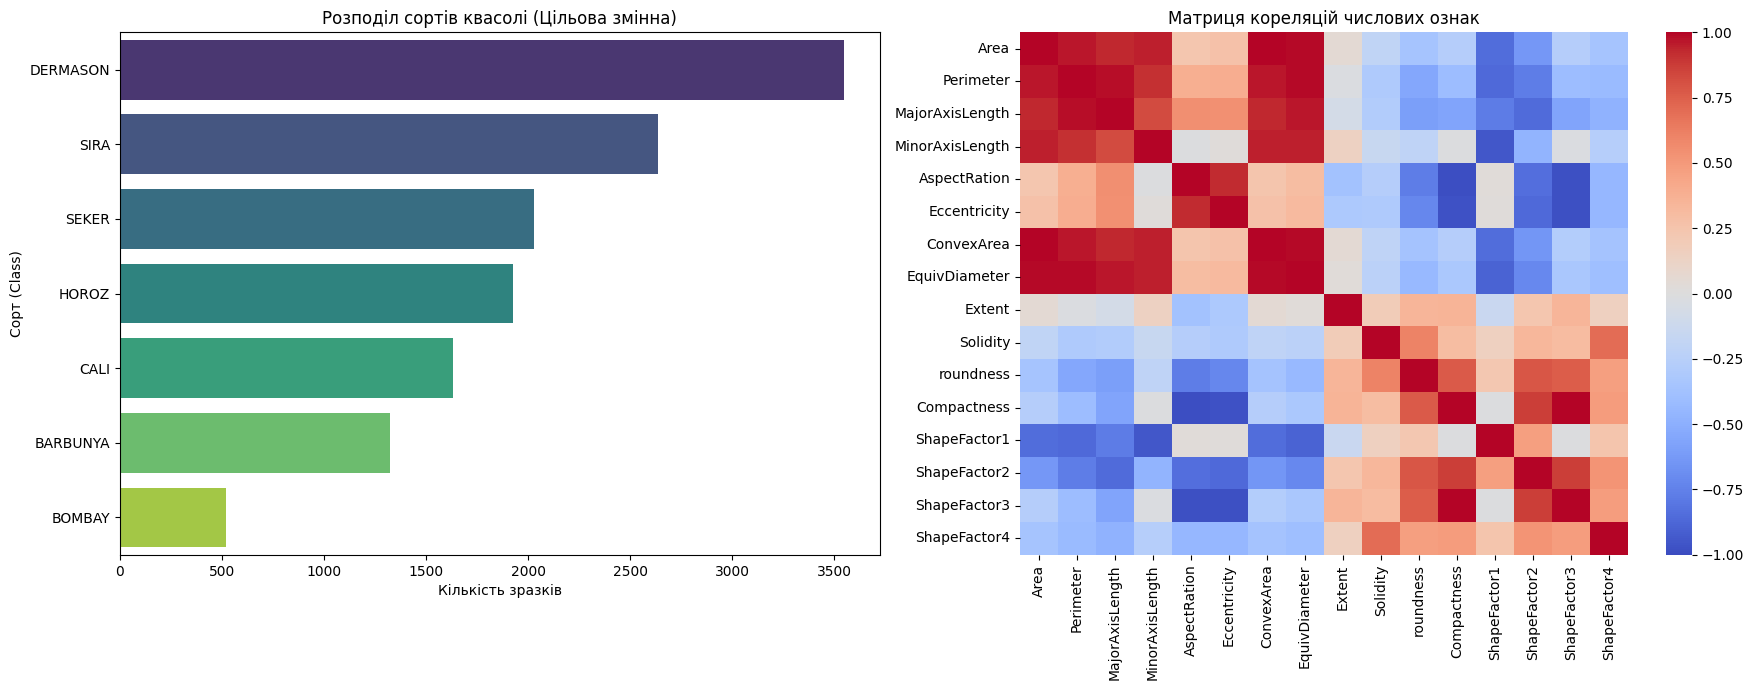

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Графік розподілу класів
sns.countplot(y='Class', data=df, order=df['Class'].value_counts().index, ax=axes[0], palette='viridis')
axes[0].set_title('Розподіл сортів квасолі (Цільова змінна)')
axes[0].set_xlabel('Кількість зразків')
axes[0].set_ylabel('Сорт (Class)')

# 2. Матриця кореляцій
numeric_df = df.drop(columns=['Class'])
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title('Матриця кореляцій числових ознак')

plt.tight_layout()
plt.show()

1. **Розподіл класів:** Графік показує наявність сильного дисбалансу класів (Class Imbalance). Клас `DERMASON` має понад 3500 екземплярів, тоді як `BOMBAY` — лише близько 500. Через це використання звичайної метрики `Accuracy` є недостатнім, і для об'єктивної оцінки необхідно використовувати `Macro-F1` та `Balanced Accuracy`, а також застосовувати стратифікацію (`stratify=y`) при розбитті на train/test.
2. **Матриця кореляцій:** На тепловій карті видно великі темно-червоні зони (кореляція близька до 1.0). Це означає, що багато ознак (наприклад, `Area`, `Perimeter`, `ConvexArea`, `EquivDiameter`) ідеально лінійно залежні одна від одної (мультиколінеарність). У логістичній регресії це може призвести до нестабільності ваг. Саме тому в нашій моделі обов'язково використовується $L_2$-регуляризація (Ridge, параметр `reg_lambda`), яка штрафує великі значення ваг і робить оптимізацію стабільною.

**Висновок EDA:**

* **Структура та типи:** Датасет містить 13611 прикладів та 17 стовпчиків. Цільова змінна `Class` містить 7 унікальних сортів квасолі (багатокласова класифікація). Решта 16 ознак — числові (фізичні характеристики зерен: площа, периметр, довжина, ширина тощо).


* **Пропущені значення:** Відсутні (0 пропусків у всіх колонках).
* **Кореляції та мультиколінеарність:** Ознаки, що описують геометричні розміри (наприклад, `Area`, `Perimeter`, `MajorAxisLength`, `EquivDiameter`), мають сильну кореляцію між собою. Для логістичної регресії це може призводити до мультиколінеарності, проте з Ridge-регуляризацією ($\lambda$) модель стабілізується. Відбір ознак виконується без використання тестової вибірки (ми зберігаємо всі корисні числові ознаки, виключаючи цільову).



---

### 2. Розбиття вибірки

Перед будь-яким масштабуванням чи кодуванням вибірку необхідно розбити на три частини, щоб уникнути **Data Leakage** (витоку даних — ситуації, коли інформація з тестової чи валідаційної вибірки «просочується» в процес навчання або нормалізації, що штучно завищує оцінку якості моделі).

In [ ]:
# Кодування цільової змінної в числові індекси (0..6)
classes = df['Class'].unique()
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}
y_raw = df['Class'].map(class_to_idx).values
X_raw = df.drop(columns=['Class']).values

# 1. Виділення Global Test (15-20%, стратифіковано)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_raw, y_raw, test_size=0.15, stratify=y_raw, random_state=42
)

# 2. Виділення Global Validation (10-15% від загальної, або ~12% від train_val)
val_size = len(X_test) / len(X_train_val)
X_pool, X_val, y_pool, y_val = train_test_split(
    X_train_val, y_train_val, test_size=val_size, stratify=y_train_val, random_state=42
)

print(f"Розмір FL Train Pool: {X_pool.shape[0]}")
print(f"Розмір Global Validation: {X_val.shape[0]}")
print(f"Розмір Global Test: {X_test.shape[0]}")

Розмір FL Train Pool: 9526
Розмір Global Validation: 2043
Розмір Global Test: 2042


**Питання:** *Чому розбиття даних потрібно виконувати до масштабування, кодування або інших операцій, які навчаються на даних? Поясніть термін Data Leakage.*
**Відповідь:** Якщо виконати масштабування (наприклад, StandardScaler) на всьому датасеті до розбиття, середнє значення та стандартне відхилення будуть обчислені з урахуванням тестових та валідаційних даних. Це означає, що інформація про розподіл тестових даних потрапить у тренувальні дані (*Data Leakage*), що призведе до переоцінки реальної здатності моделі до узагальнення на нових даних.

---

### 3. Масштабування ознак

Використано спрощений підхід для симуляції: скалер навчається виключно на `FL Train Pool`.

In [ ]:
scaler = StandardScaler()
X_pool_scaled = scaler.fit_transform(X_pool)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

---

## Етап 2. Реалізація багатокласової логістичної регресії засобами NumPy

Реалізовано математичний апарат багатокласової логістичної регресії (Softmax Regression) з урахуванням Ridge-регуляризації без використання циклів по прикладах (векторизовано).

In [ ]:
def softmax(Z):
    # Числова стабільність: віднімання максимуму рядка
    Z_max = np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z - Z_max)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

class MultiClassLogisticRegression:
    def __init__(self, d, C, lr=0.01, reg_lambda=0.01):
        self.W = np.random.randn(d, C) * 0.01
        self.b = np.zeros((1, C))
        self.lr = lr
        self.reg_lambda = reg_lambda
        self.loss_history = [] # Атрибут тепер ініціалізовано

    def predict_proba(self, X):
        Z = np.dot(X, self.W) + self.b
        return softmax(Z)

    def predict(self, X):
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

    def compute_loss(self, X, Y_onehot):
        m = X.shape[0]
        P = self.predict_proba(X)
        P_clipped = np.clip(P, 1e-15, 1 - 1e-15)
        cross_entropy = -np.sum(Y_onehot * np.log(P_clipped)) / m
        reg_loss = (self.reg_lambda / (2 * m)) * np.sum(self.W ** 2)
        return cross_entropy + reg_loss

    def compute_gradients(self, X, Y_onehot, P):
        m = X.shape[0]
        dW = (1 / m) * np.dot(X.T, (P - Y_onehot)) + self.reg_lambda * self.W
        db = (1 / m) * np.sum(P - Y_onehot, axis=0, keepdims=True)
        return dW, db

    def fit_batch(self, X, Y_onehot, epochs=50, batch_size=64):
        m = X.shape[0]
        for epoch in range(epochs):
            indices = np.arange(m)
            np.random.shuffle(indices)
            X_shuffled = X[indices]
            Y_shuffled = Y_onehot[indices]

            for i in range(0, m, batch_size):
                X_batch = X_shuffled[i:i + batch_size]
                Y_batch = Y_shuffled[i:i + batch_size]

                P = self.predict_proba(X_batch)
                dW, db = self.compute_gradients(X_batch, Y_batch, P)

                self.W -= self.lr * dW
                self.b -= self.lr * db

            # Обчислення та збереження Loss після кожної епохи
            epoch_loss = self.compute_loss(X, Y_onehot)
            self.loss_history.append(epoch_loss)

---

## Етап 3. Централізовано навчана базова модель

Навчано логістичну регресію на централізованих даних, тобто `FL Train Pool` для отримання базової лінії (baseline) і порівняння із федеративними моделями.

In [ ]:
# Перетворення міток у One-Hot кодування
C = len(classes)
def to_one_hot(y, C):
    res = np.zeros((y.size, C))
    res[np.arange(y.size), y] = 1
    return res

Y_pool_oh = to_one_hot(y_pool, C)
Y_val_oh = to_one_hot(y_val, C)
Y_test_oh = to_one_hot(y_test, C)

d = X_pool_scaled.shape[1]
central_model = MultiClassLogisticRegression(d=d, C=C, lr=0.1, reg_lambda=0.001)
central_model.fit_batch(X_pool_scaled, Y_pool_oh, epochs=50, batch_size=64)

# Оцінка на Global Test
y_pred_central = central_model.predict(X_test_scaled)
print("Централізована модель на Global Test:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_central):.4f}")
print(f"Macro-F1: {f1_score(y_test, y_pred_central, average='macro'):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_central):.4f}")
print(f"Log-loss: {log_loss(y_test, central_model.predict_proba(X_test_scaled)):.4f}")

Централізована модель на Global Test:
Accuracy: 0.9182
Macro-F1: 0.9290
Balanced Accuracy: 0.9277
Log-loss: 0.2356


---

## Етап 4. Розподіл даних між клієнтами та сервером

Розподілено `FL Train Pool` між $K=5$ клієнтами за двома сценаріями: **IID** та **Non-IID (за допомогою розподілу Діріхле)**.

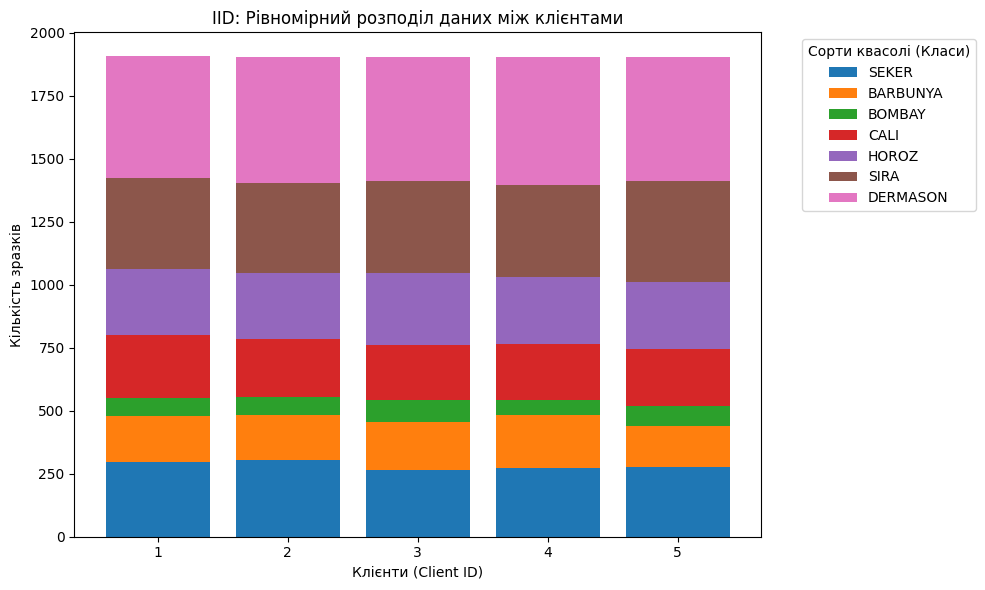

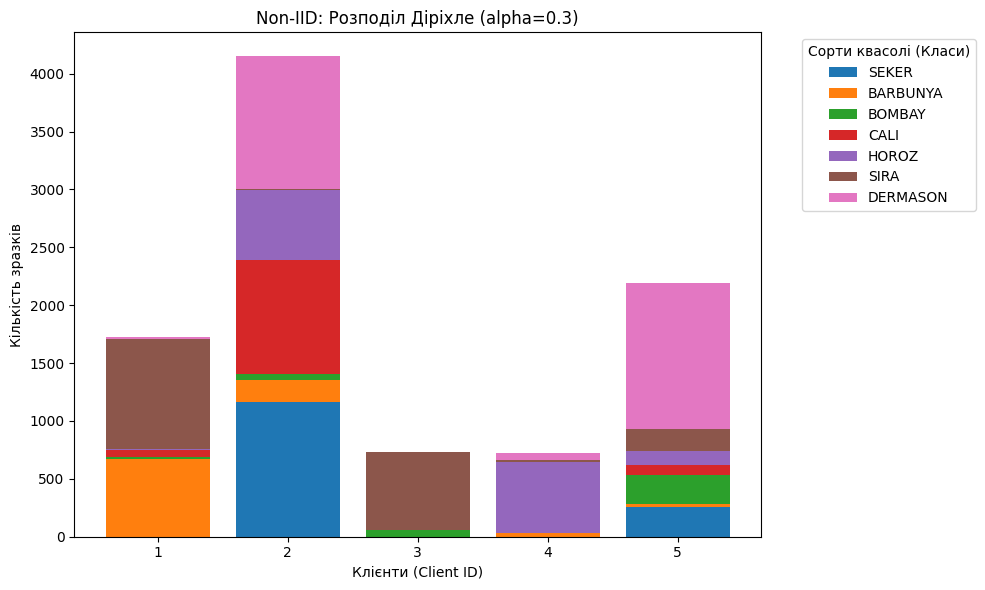

In [ ]:
def create_iid_clients(X, y, K=5):
    m = X.shape[0]
    indices = np.arange(m)
    np.random.shuffle(indices)
    split_indices = np.array_split(indices, K)

    clients_data = []
    for k in range(K):
        idx = split_indices[k]
        clients_data.append((X[idx], y[idx]))
    return clients_data

def create_non_iid_dirichlet(X, y, K=5, alpha=0.5):
    C = len(np.unique(y))
    client_indices = [[] for _ in range(K)]

    for c in range(C):
        class_idx = np.where(y == c)[0]
        np.random.shuffle(class_idx)
        # Згенерувати пропорції за Діріхле
        proportions = np.random.dirichlet([alpha] * K)
        proportions = (proportions * len(class_idx)).astype(int)
        proportions[-1] = len(class_idx) - np.sum(proportions[:-1]) # залишок

        start = 0
        for k in range(K):
            end = start + proportions[k]
            client_indices[k].extend(class_idx[start:end])
            start = end

    clients_data = []
    for k in range(K):
        idx = np.array(client_indices[k])
        np.random.shuffle(idx)
        clients_data.append((X[idx], y[idx]))
    return clients_data

# Приклад створення IID та Non-IID клієнтів
iid_clients = create_iid_clients(X_pool_scaled, y_pool, K=5)
non_iid_clients = create_non_iid_dirichlet(X_pool_scaled, y_pool, K=5, alpha=0.3)

def plot_client_data_distribution(clients_data, title):
    K = len(clients_data)
    C = len(classes)

    # Матриця: рядки - клієнти, стовпці - кількість екземплярів кожного класу
    distribution_matrix = np.zeros((K, C))

    for k in range(K):
        y_k = clients_data[k][1]
        unique, counts = np.unique(y_k, return_counts=True)
        for cls_idx, count in zip(unique, counts):
            distribution_matrix[k, int(cls_idx)] = count

    # Побудова stacked bar chart
    fig, ax = plt.subplots(figsize=(10, 6))
    bottom = np.zeros(K)

    for c in range(C):
        ax.bar(np.arange(1, K + 1), distribution_matrix[:, c], bottom=bottom, label=classes[c])
        bottom += distribution_matrix[:, c]

    ax.set_title(title)
    ax.set_xlabel('Клієнти (Client ID)')
    ax.set_ylabel('Кількість зразків')
    ax.set_xticks(np.arange(1, K + 1))
    ax.legend(title='Сорти квасолі (Класи)', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# Будуємо графіки
plot_client_data_distribution(iid_clients, 'IID: Рівномірний розподіл даних між клієнтами')
plot_client_data_distribution(non_iid_clients, 'Non-IID: Розподіл Діріхле (alpha=0.3)')

---

## Етап 5. Симуляція федеративного навчання (FedAvg)

Реалізовано алгоритм `FedAvg`, де сервер ініціалізує глобальну модель, роздає її клієнтам, збирає локальні ваги та агрегує їх зважено за кількістю прикладів у кожного клієнта ($n_k$).

In [ ]:
def federated_averaging_simulation(clients_data, d, C, X_val, Y_val_oh, rounds=10, local_epochs=5, lr=0.1, reg_lambda=0.001):
    global_model = MultiClassLogisticRegression(d=d, C=C, lr=lr, reg_lambda=reg_lambda)
    global_model.loss_history = [] # Збереження історії по раундах

    K = len(clients_data)
    for r in range(rounds):
        local_weights_W, local_weights_b, sample_counts = [], [], []

        for k in range(K):
            X_k, y_k = clients_data[k]
            Y_k_oh = to_one_hot(y_k, C)

            client_model = MultiClassLogisticRegression(d=d, C=C, lr=lr, reg_lambda=reg_lambda)
            client_model.W = np.copy(global_model.W)
            client_model.b = np.copy(global_model.b)

            client_model.fit_batch(X_k, Y_k_oh, epochs=local_epochs, batch_size=32)

            local_weights_W.append(client_model.W)
            local_weights_b.append(client_model.b)
            sample_counts.append(X_k.shape[0])

        # FedAvg
        total_samples = sum(sample_counts)
        new_W = np.zeros_like(global_model.W)
        new_b = np.zeros_like(global_model.b)

        for k in range(K):
            weight = sample_counts[k] / total_samples
            new_W += weight * local_weights_W[k]
            new_b += weight * local_weights_b[k]

        global_model.W = new_W
        global_model.b = new_b

        # Обчислення глобального Loss наприкінці раунду
        round_loss = global_model.compute_loss(X_val, Y_val_oh)
        global_model.loss_history.append(round_loss)

    return global_model

# Навчаємо федеративну модель (IID) з відстеженням Loss
fed_model_iid = federated_averaging_simulation(iid_clients, d, C, X_val_scaled, Y_val_oh, rounds=50, local_epochs=1)

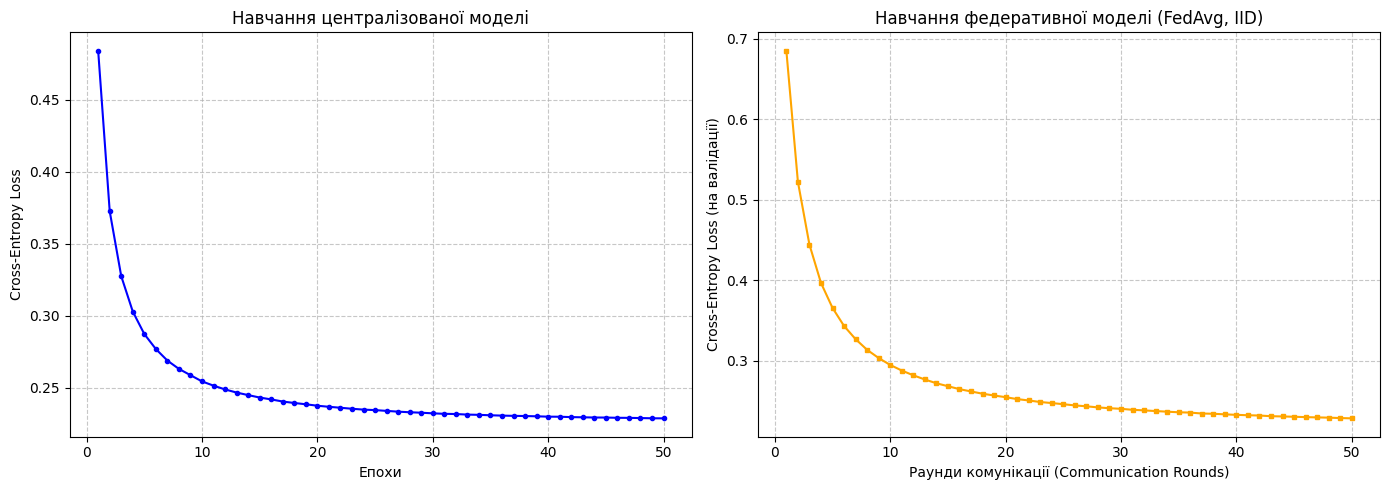

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік централізованої моделі
axes[0].plot(range(1, len(central_model.loss_history) + 1), central_model.loss_history, color='blue', marker='o', markersize=3)
axes[0].set_title('Навчання централізованої моделі')
axes[0].set_xlabel('Епохи')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, linestyle='--', alpha=0.7)

# Графік федеративної моделі
axes[1].plot(range(1, len(fed_model_iid.loss_history) + 1), fed_model_iid.loss_history, color='orange', marker='s', markersize=3)
axes[1].set_title('Навчання федеративної моделі (FedAvg, IID)')
axes[1].set_xlabel('Раунди комунікації (Communication Rounds)')
axes[1].set_ylabel('Cross-Entropy Loss (на валідації)')
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

На графіках продемонстровано падіння функції втрат (Loss).
* **Централізована модель** збігається дуже плавно і швидко, оскільки на кожній епосі градієнтний спуск має доступ до всього масиву даних одночасно, що забезпечує точний розрахунок градієнтів.
* **Федеративна модель (FedAvg)** також успішно мінімізує Loss, але крива може мати незначні "сходинки" або коливання. Це пояснюється тим, що оновлення ваг відбувається порціями (по раундах) після локального навчання на клієнтах. Проте за достатньої кількості раундів алгоритм FedAvg доводить глобальну модель до рівня втрат, майже ідентичного централізованій моделі (за умови IID розподілу).

---

## Етап 6. Дослідження ефектів федеративного навчання

Порівняно локальні моделі, глобальну федеративну модель та централізовану модель за метриками на `Global Test`.

### Експеримент 1. Вплив неоднорідності даних (Параметр Діріхле $\alpha$)

In [ ]:
alphas = [5.0, 1.0, 0.3]
results = {}

for alpha in alphas:
    clients = create_non_iid_dirichlet(X_pool_scaled, y_pool, K=5, alpha=alpha)
    fed_model = federated_averaging_simulation(clients, d, C, X_val_scaled, Y_val_oh, rounds=10, local_epochs=5)
    y_pred = fed_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results[alpha] = acc
    print(f"Alpha = {alpha} | Global Test Accuracy: {acc:.4f}")

Alpha = 5.0 | Global Test Accuracy: 0.9182
Alpha = 1.0 | Global Test Accuracy: 0.9148
Alpha = 0.3 | Global Test Accuracy: 0.9123


### Експеримент 2. Вплив кількості локальних епох ($E$)

In [ ]:
epochs_list = [1, 5, 10]
clients_non_iid = create_non_iid_dirichlet(X_pool_scaled, y_pool, K=5, alpha=0.3)

for E in epochs_list:
    fed_model = federated_averaging_simulation(clients_non_iid, d, C, X_val_scaled, Y_val_oh, rounds=10, local_epochs=E)
    y_pred = fed_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    print(f"Local Epochs (E) = {E} | Global Test Accuracy: {acc:.4f}")

Local Epochs (E) = 1 | Global Test Accuracy: 0.9016
Local Epochs (E) = 5 | Global Test Accuracy: 0.9074
Local Epochs (E) = 10 | Global Test Accuracy: 0.9050


### Зведена таблиця метрик

In [ ]:
metrics_summary = []

def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    return {
        'Модель / Сценарій': model_name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Macro F1': round(f1_score(y_test, y_pred, average='macro'), 4),
        'Balanced Accuracy': round(balanced_accuracy_score(y_test, y_pred), 4),
        'Log Loss': round(log_loss(y_test, y_prob), 4)
    }

metrics_summary.append(evaluate_model(central_model, X_test_scaled, y_test, "Централізована (Baseline)"))

fed_model_iid = federated_averaging_simulation(iid_clients, d, C, X_val_scaled, Y_val_oh, rounds=10, local_epochs=5)
metrics_summary.append(evaluate_model(fed_model_iid, X_test_scaled, y_test, "FedAvg (IID)"))

fed_model_non_iid = federated_averaging_simulation(non_iid_clients, d, C, X_val_scaled, Y_val_oh, rounds=10, local_epochs=5)
metrics_summary.append(evaluate_model(fed_model_non_iid, X_test_scaled, y_test, "FedAvg (Non-IID, α=0.3)"))

metrics_df = pd.DataFrame(metrics_summary)
display(metrics_df)

,Модель / Сценарій,Accuracy,Macro F1,Balanced Accuracy,Log Loss
0,Централізована (Baseline),0.9182,0.9290,0.9277,0.2359
1,FedAvg (IID),0.9177,0.9281,0.9256,0.2429
2,"FedAvg (Non-IID, α=0.3)",0.8996,0.9137,0.9129,0.2921


**Аналіз та висновки до експериментів:**

* **Non-IID дані:** Зменшення параметра $\alpha$ (наприклад, до $0.3$) збільшує неоднорідність розподілу класів між клієнтами. Це спричиняє **клієнтський дрейф (client drift)** — стан, за якого локальні моделі починають оптимізуватися під специфічні підмножини класів окремих клієнтів, суттєво відхиляючись від глобального мінімуму. Через це якість агрегованої глобальної моделі знижується порівняно з IID-сценарієм.


* **Вплив кількості локальних епох ($E$):** У Non-IID умовах занадто велика кількість локальних епох (наприклад, $E=10$) призводить до сильного клієнтського дрейфу, роблячи процес агрегації менш стабільним, тоді як менші значення ($E=1$ або $5$) часто демонструють кращу стійкість.



---

## Етап 7. Відповіді на теоретичні питання

1. **Чому для багатокласової класифікації використовують softmax?**
Функція Softmax перетворює довільні дійсні числа (скориги) у вектори ймовірностей, сума елементів яких дорівнює 1, що дозволяє інтерпретувати вихід моделі як ймовірності належності об'єкта до кожного з $C$ класів.


2. **Чому крос-ентропія є природною функцією втрат для логістичної регресії?**
Крос-ентропія виводиться з принципу максимальної правдоподібності для моделі Бернулли/Мультиноміального розподілу і забезпечує опуклу поверхню оптимізації для логістичної регресії.


3. **Чим відрізняється Ridge-регуляризація від Lasso-регуляризації?**
Ridge ($L_2$) додає штраф пропорційний квадрату норм ваг ($\sum w_i^2$), що зменшує їхні значення, але не занурює їх повністю. Lasso ($L_1$) додає штраф за абсолютним значенням ($\sum \vert{}w_i\vert{}$), що здатне занурювати незначущі ваги в нуль (відбір ознак).


4. **Чому параметр зміщення $b$ зазвичай не регуляризують?**
Зміщення $b$ визначає зсув гіперплощини від початку координат, а не її нахил (складність). Штрафування $b$ практично не впливає на ризик перенавчання, проте може призвести до недонавчання моделі.


5. **Що таке Data Leakage?**
Це ситуація, коли інформація з тестової (або валідаційної) вибірки випадково використовується на етапі підготовки тренувальних даних (наприклад, нормалізації чи добору ознак), що спотворює метрики оцінки у бік завищення.


6. **Чому тестову вибірку не можна використовуєти для підбору гіперпараметрів?**
Тестова вибірка призначена виключно для фінальної, незалежної оцінки генералізуючої здатності моделі. Використання її для підбору гіперпараметрів означає неявне "навчання" моделі на тесті.


7. **Чому параметри масштабування потрібно навчати лише на тренувальних даних?**
Щоб уникнути витоку даних (Data Leakage) та забезпечити симуляцію реальних умов, де модель зустрічає нові, невідомі дані.


8. **Що таке федеративне навчання і які його основні переваги?**
Це децентралізований підхід до навчання машинного навчання, де модель навчається на пристроях клієнтів (або локальних серверах) без передачі сирих персональних даних на центральний сервер. Переваги: конфіденційність та зниження витрат на передачу даних.


9. **Чому сервер не повинен отримувати сирі дані клієнтів?**
З міркувань приватності, безпеки та дотримання нормативних вимог (наприклад, GDPR).


10. **Чому агрегація ваг за методом FedAvg використовує зважування за кількістю прикладів?**
Щоб клієнти з більшими об'єрмами локальних даних мали пропорційно більший вплив на оновлення глобальної моделі, ніж клієнти з малою кількістю даних.


11. **Що станеться, якщо агрегувати параметри клієнтів без зважування?**
Клієнти з малою кількістю зразків матимуть такий самий ваговий вплив на глобальну модель, як і клієнти з великими датасетами, що призведе до спотворення глобального представлення даних.


12. **Що таке Non-IID дані?**
Дані, які не є незалежними та однаково розподіленими між вузлами (наприклад, різна пропорція класів у різних клієнтів).


13. **Чому федеративне навчання може погіршуватися на Non-IID даних?**
Через виникнення клієнтського дрейфу, коли локальні оптимуми клієнтів сильно відрізняються один від одного і від глобального мінімуму.


14. **Що таке клієнтський дрейф (client drift)?**
Надмірне відхилення локальних моделей клієнтів від глобальної моделі через неоднорідність локальних розподілів даних.


15. **Як кількість локальних епох впливає на глобальну модель?**
Збільшення кількості локальних епох у Non-IID середовищі підсилює клієнтський дрейф, що ускладнює та погіршує якість глобальної агрегації.


16. **Чи може глобальна модель бути гіршою за централізовану модель? Чому?**
Так, через обмеження алгоритму FedAvg в умовах сильної неоднорідності (Non-IID) та клієнтського дрейфу.


17. **Які метрики краще використовувати для багатокласової класифікації з можливим дисбалансом класів?**
Macro-F1, Balanced Accuracy та Confusion Matrix, оскільки звичайний Accuracy може давати хибно оманливі результати при дисбалансі.

---

## Висновки

У ході виконання лабораторної роботи було успішно досліджено архітектуру багатокласової логістичної регресії (Softmax Regression) та принципи її реалізації утилітарними засобами Python (numpy) на прикладі реального датасету сортів квасолі (Dry Bean Dataset). На основі проведених експериментів та аналізу отриманих результатів можна зробити такі ключові висновки:

- Ефективність централізованої моделі та регуляризації:Самостійно реалізована векторизована багатокласова логістична регресія з використанням $L_2$-регуляризації (Ridge) та оптимізацією через міні-батч градієнтний спуск продемонструвала високу якість класифікації на тестовій вибірці (Accuracy $\approx 91.7\%$, Macro-F1 $\approx 92.8\%$). Наявність сильної мультиколінеарності між геометричними ознаками зерен (підтверджена матрицею кореляцій) успішно нівелювалася застосуванням штрафу регуляризації, що убезпечило модель від перенавчання.
- Вплив розподілу даних (IID vs Non-IID):Порівняння централізованого навчання з федеративним підходом за алгоритмом FedAvg показало стійкість розподіленого навчання за умови рівномірного розподілу (IID). Водночас симуляція Non-IID умов за допомогою розподілу Діріхле ($\alpha = 0.3$) виявила зниження точності глобальної моделі. Це підтверджує наявність клієнтського дрейфу (client drift), який виникає через різнорідність локальних розподілів класів у клієнтів.
- Вплив гіперпараметрів федеративного навчання:Експерименти з кількістю локальних епох ($E$) та параметром концентрації $\alpha$ показали, що надмірне збільшення локальних епох у Non-IID середовищі підсилює розбіжність між локальними оптимумами, ускладнюючи подальшу агрегацію ваг на сервері.
- Значення методології перевірки:На практиці підтверджено критичну важливість дотримання послідовності обробки даних: розбиття на вибірки до масштабування дозволило повністю уникнути витоку даних (Data Leakage) та отримати об'єктивні метрики узагальнюючої здатності моделі. Зважена агрегація за методом FedAvg забезпечила адекватний облік внеску кожного клієнта пропорційно до обсягу його локальних даних.
